In [2]:
!pip -q install kaggle

In [4]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle token: ")

Paste your Kaggle token: ··········


In [5]:
!kaggle datasets download -d mlg-ulb/creditcardfraud -p /content

Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 125MB/s]



In [6]:
!unzip -oq /content/creditcardfraud.zip -d /content

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("/content/creditcard.csv")

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
print(df.describe())

print("\ndataset info")
print(df.info())

print("\nTarget distribution:")
if "Class" in df.columns:
    print(df["Class"].value_counts())
    print(df["Class"].value_counts(normalize=True) * 100)


Dataset shape: (284807, 31)

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Column names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Missing values:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0


In [10]:

# Find rows that are exact duplicates of earlier rows
duplicate_mask = df.duplicated()

print("Total duplicate rows:", duplicate_mask.sum())

# Inspect the class labels of rows that would be removed
print("\nClass distribution among duplicate rows:")
print(df.loc[duplicate_mask, "Class"].value_counts())

# Display a few duplicate rows
print("\nSample duplicate rows:")
display(df.loc[duplicate_mask].head())

# Compare class distribution before removing anything
print("\nOriginal class distribution:")
print(df["Class"].value_counts())


Total duplicate rows: 1081

Class distribution among duplicate rows:
Class
0    1062
1      19
Name: count, dtype: int64

Sample duplicate rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0



Original class distribution:
Class
0    284315
1       492
Name: count, dtype: int64


In [11]:
# Store the original dataset size
original_shape = df.shape

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Original dataset shape:", original_shape)
print("Shape after removing duplicates:", df.shape)
print("Rows removed:", original_shape[0] - df.shape[0])

print("\nClass distribution after cleaning:")
print(df["Class"].value_counts())

print("\nClass percentages after cleaning:")
print(df["Class"].value_counts(normalize=True) * 100)

print("\nRemaining duplicate rows:", df.duplicated().sum())


Original dataset shape: (284807, 31)
Shape after removing duplicates: (283726, 31)
Rows removed: 1081

Class distribution after cleaning:
Class
0    283253
1       473
Name: count, dtype: int64

Class percentages after cleaning:
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64

Remaining duplicate rows: 0


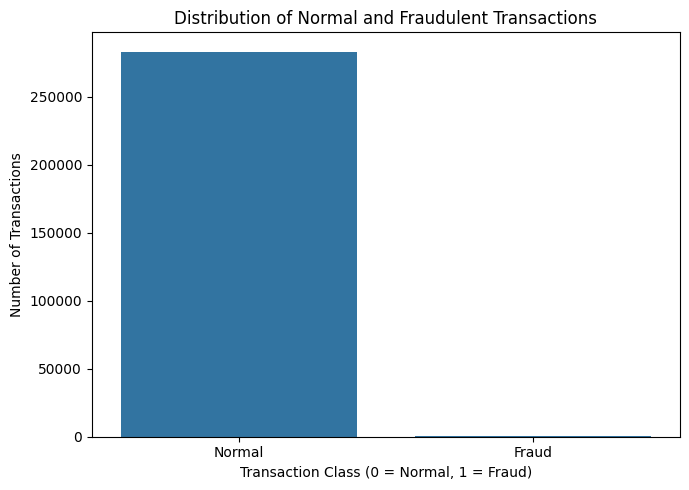

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Distribution of Normal and Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.tight_layout()
plt.show()

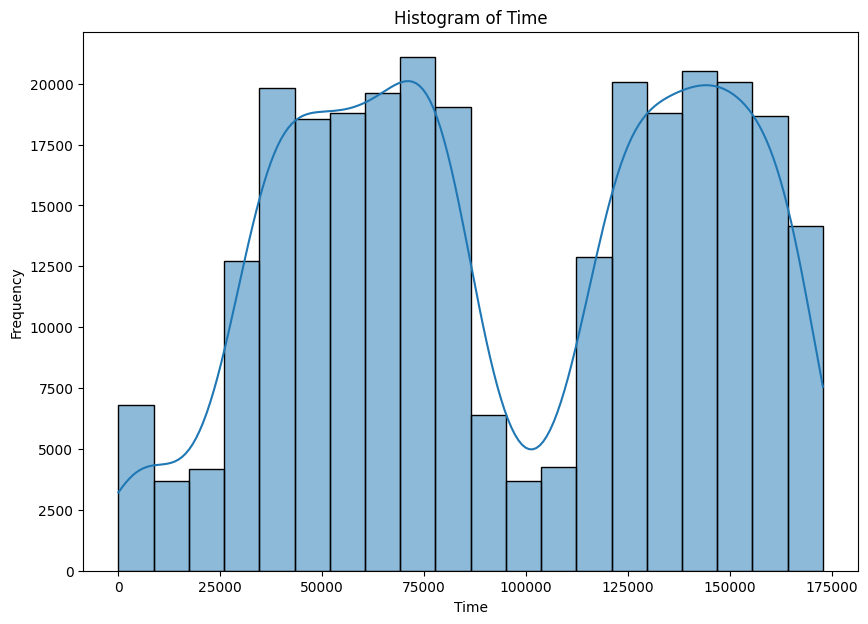

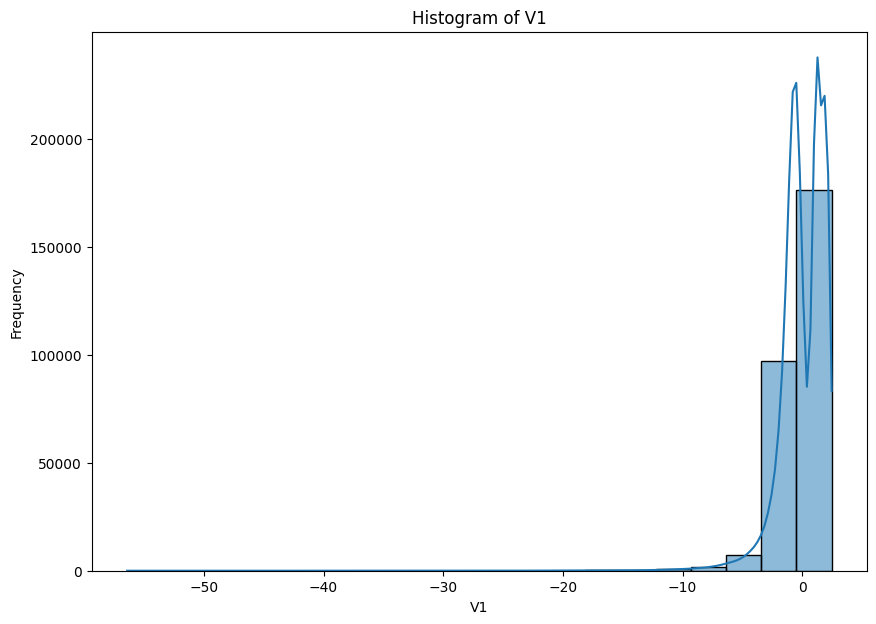

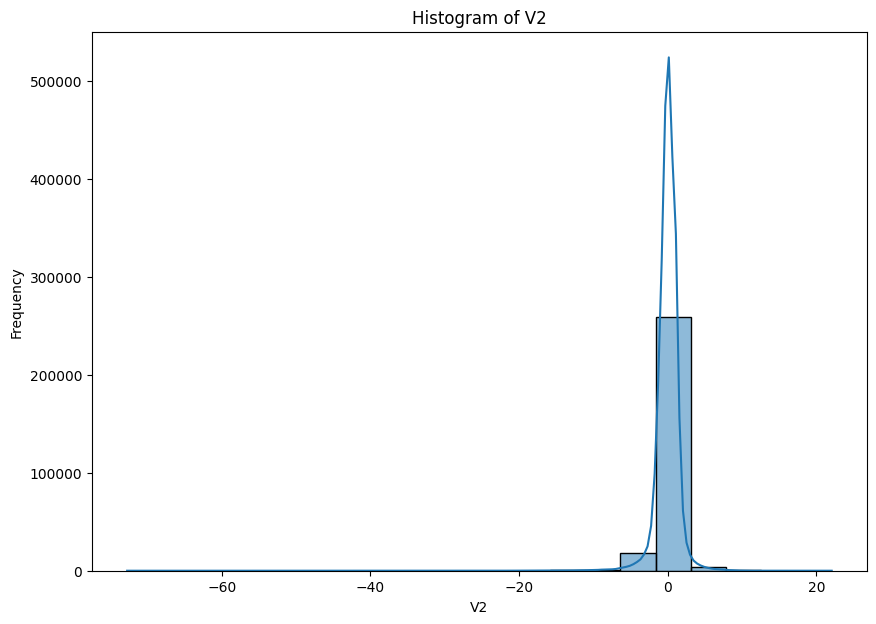

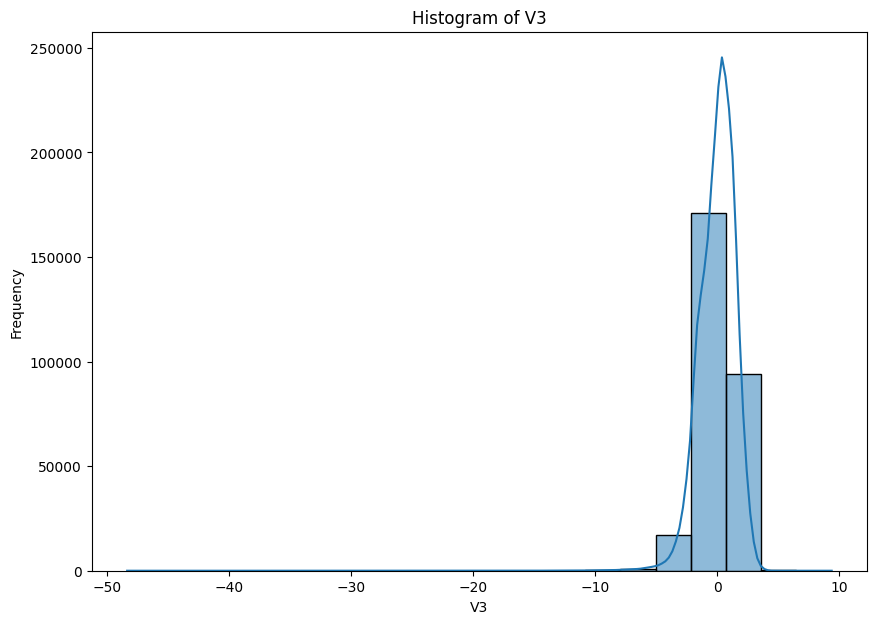

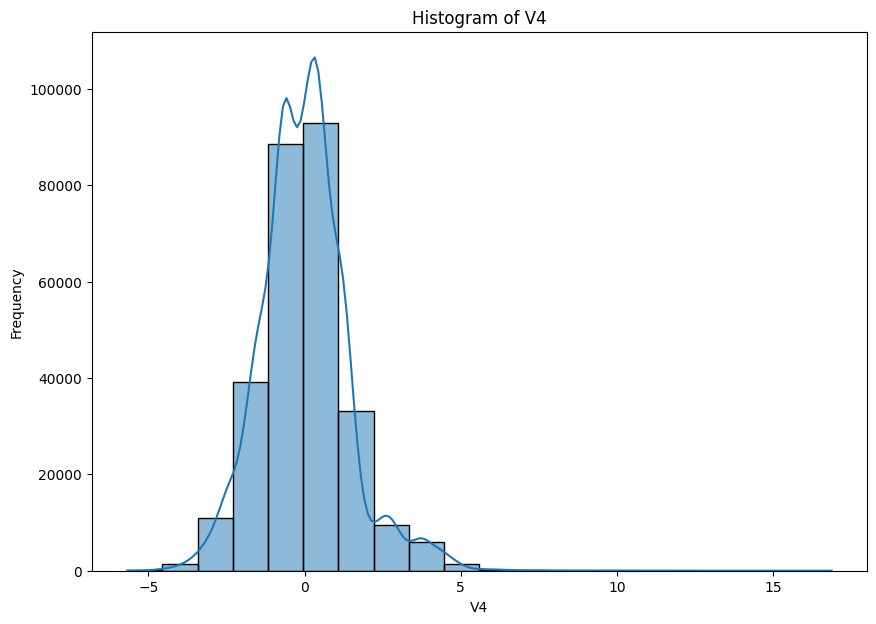

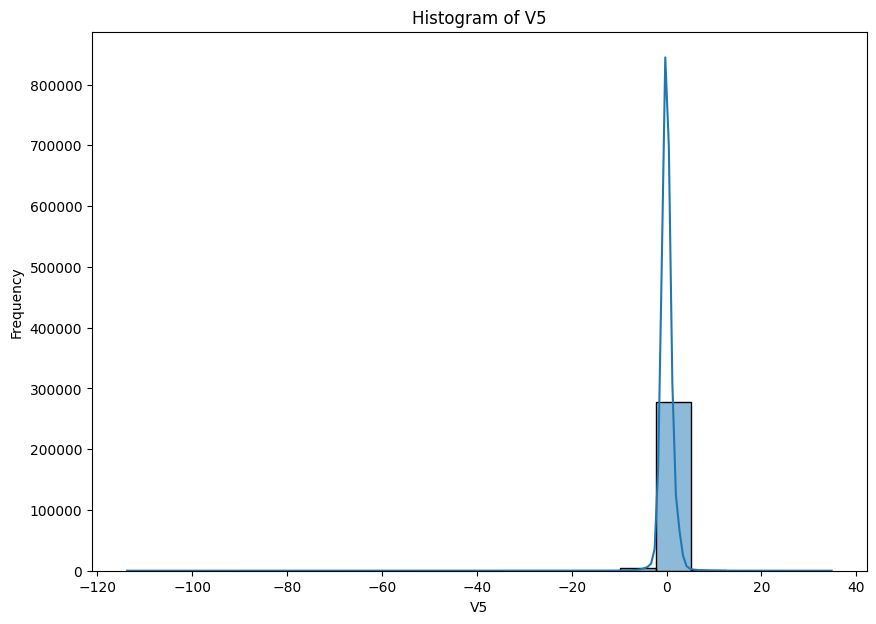

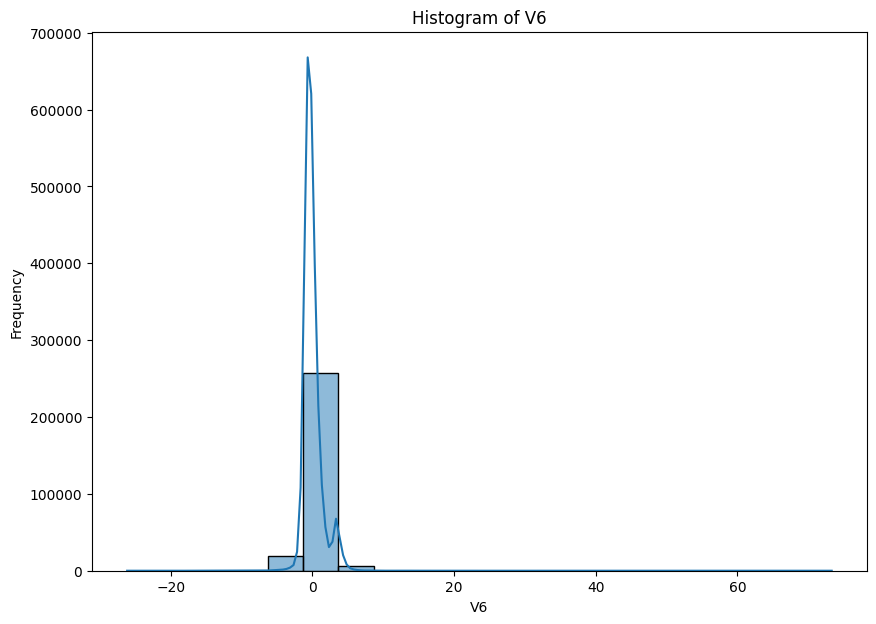

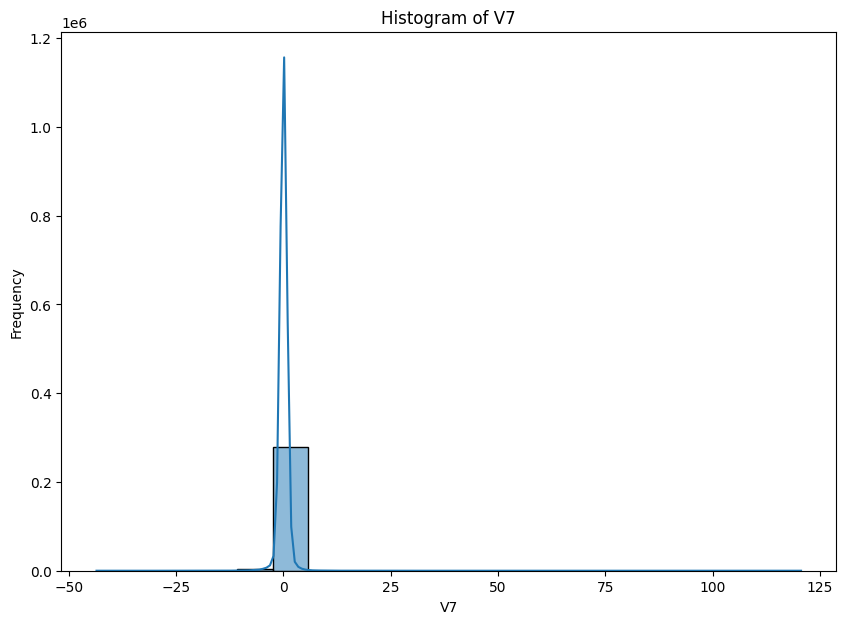

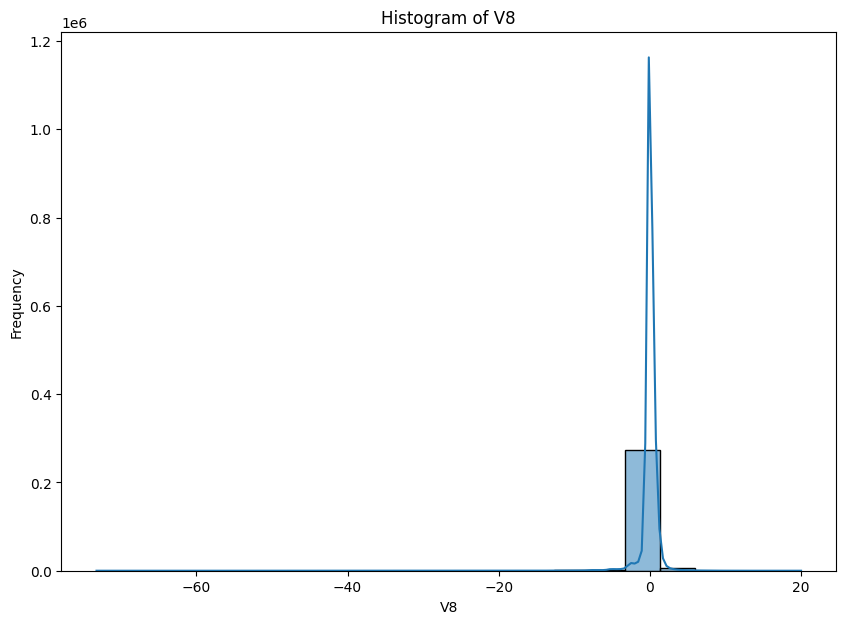

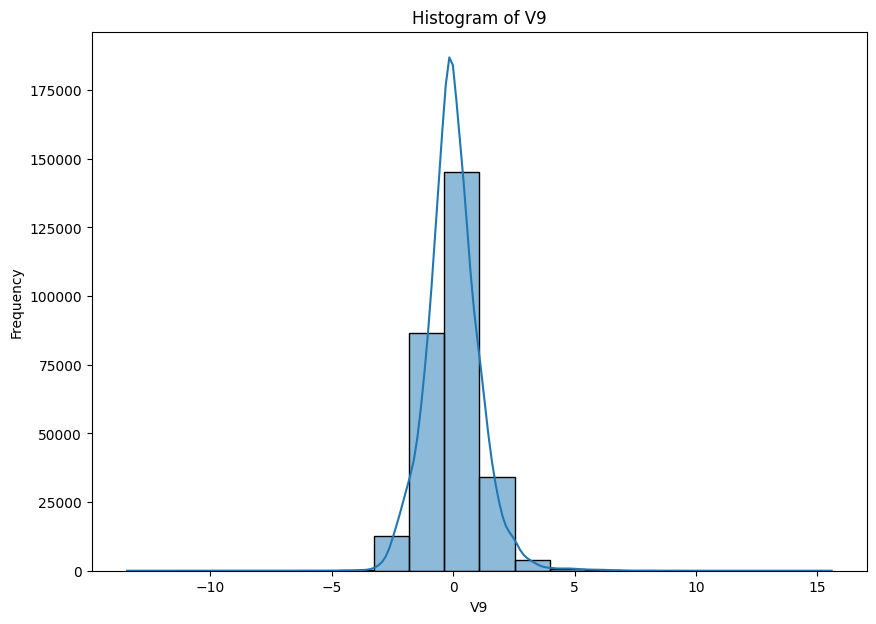

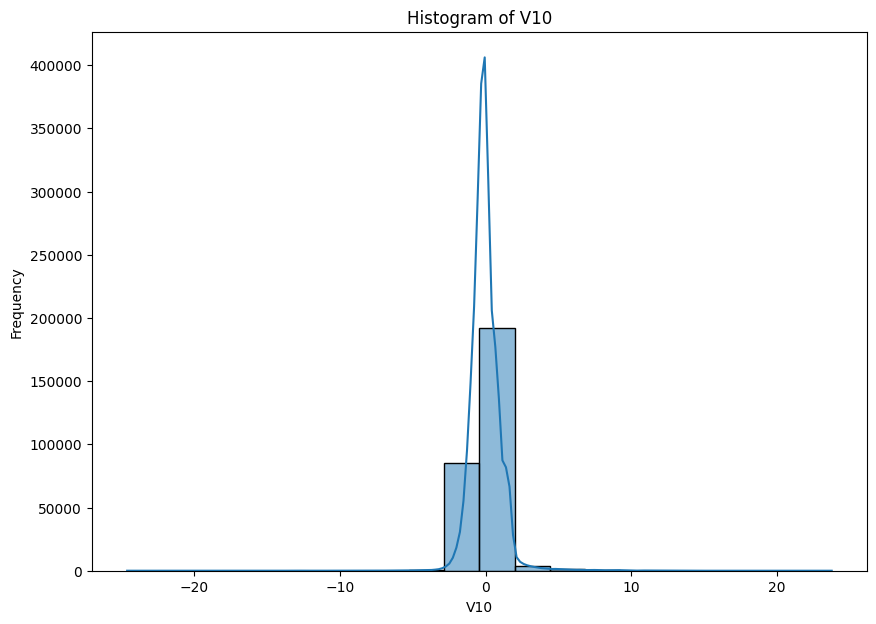

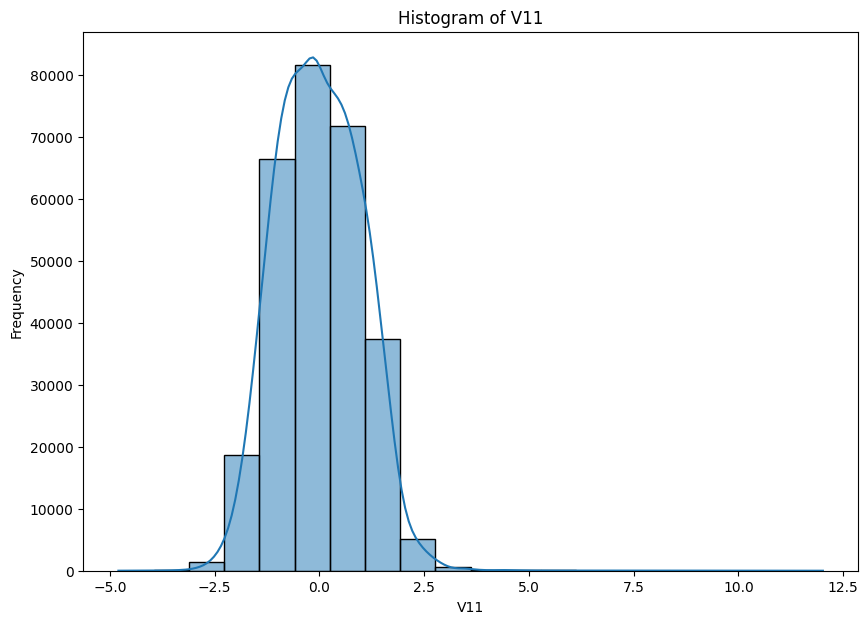

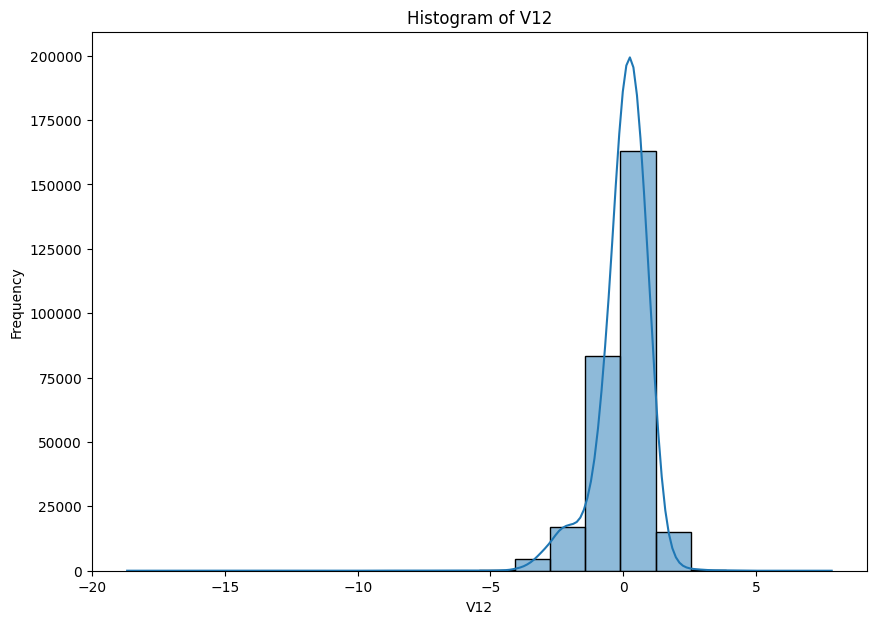

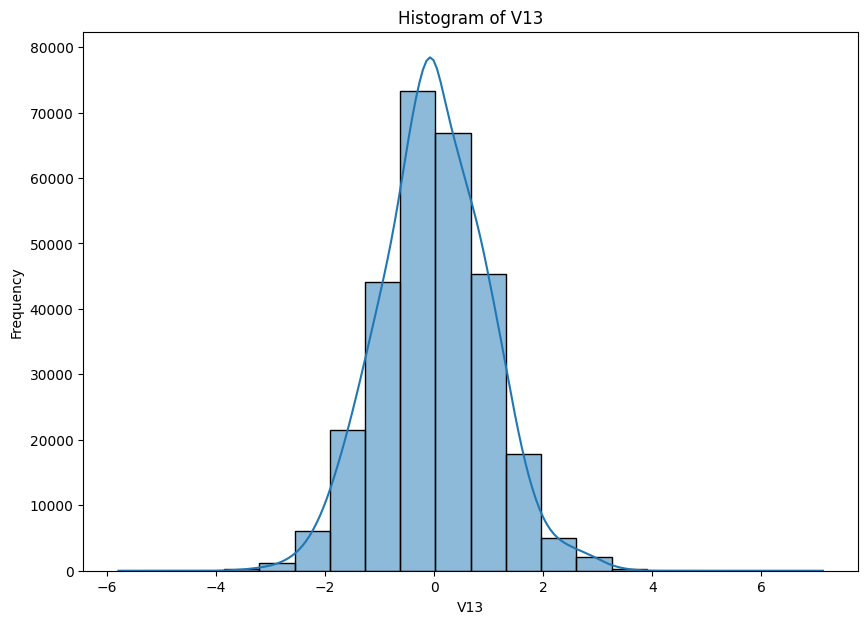

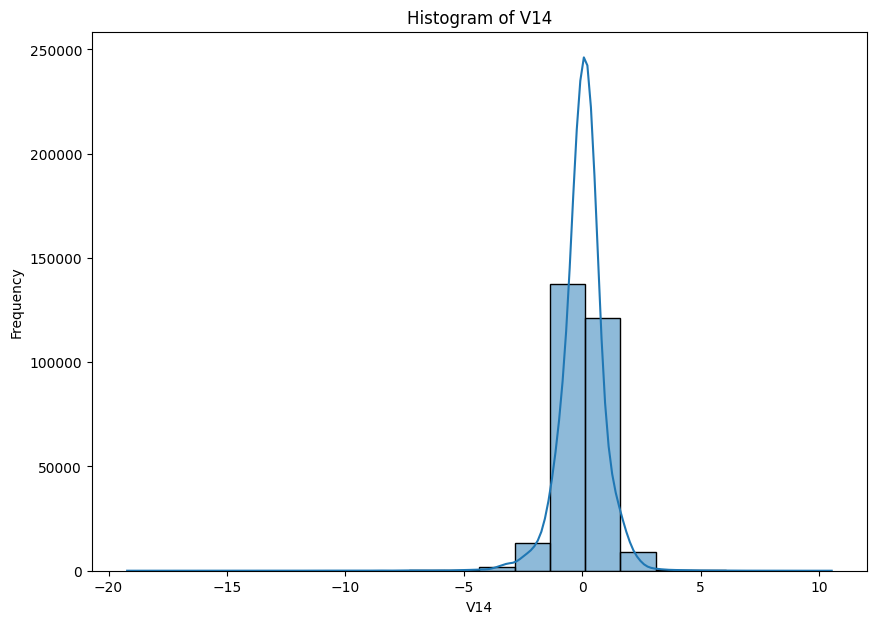

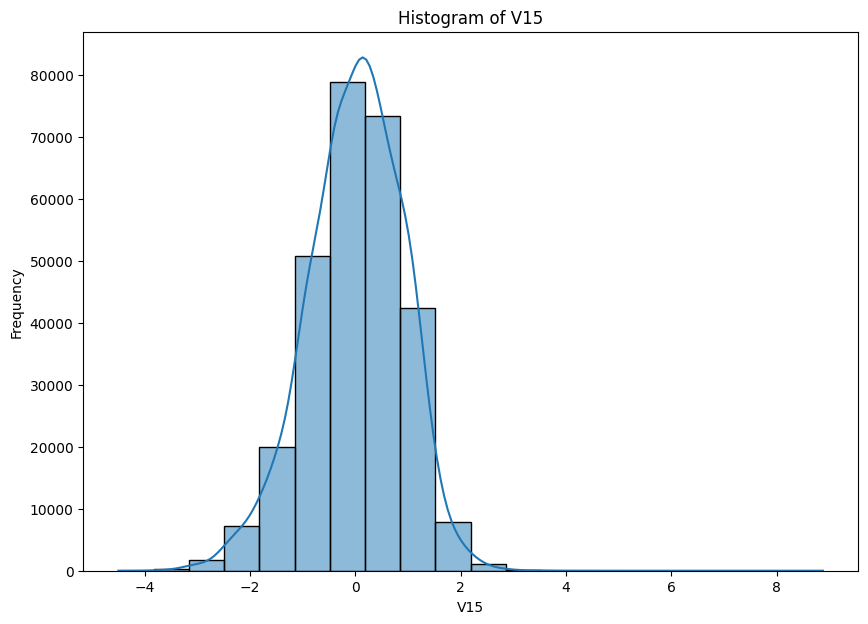

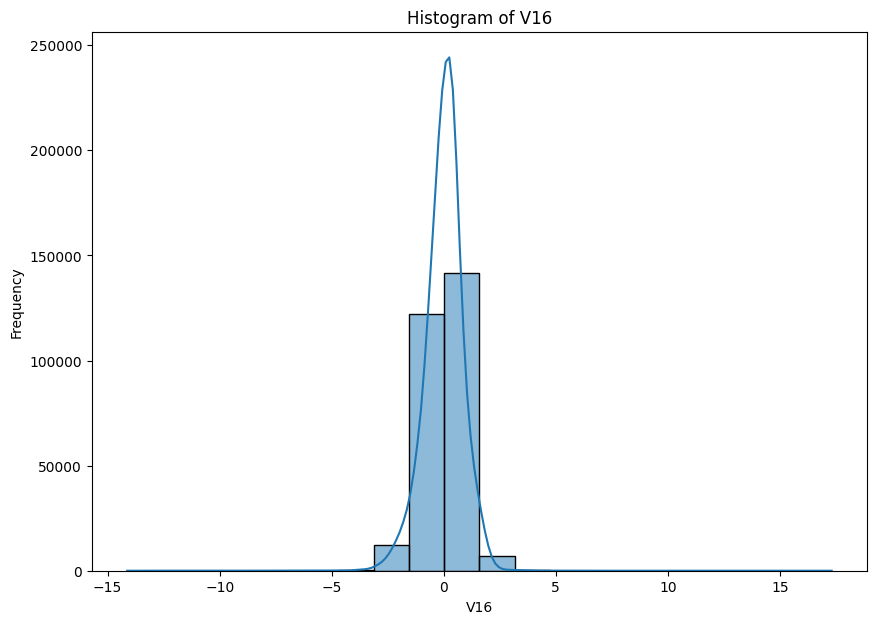

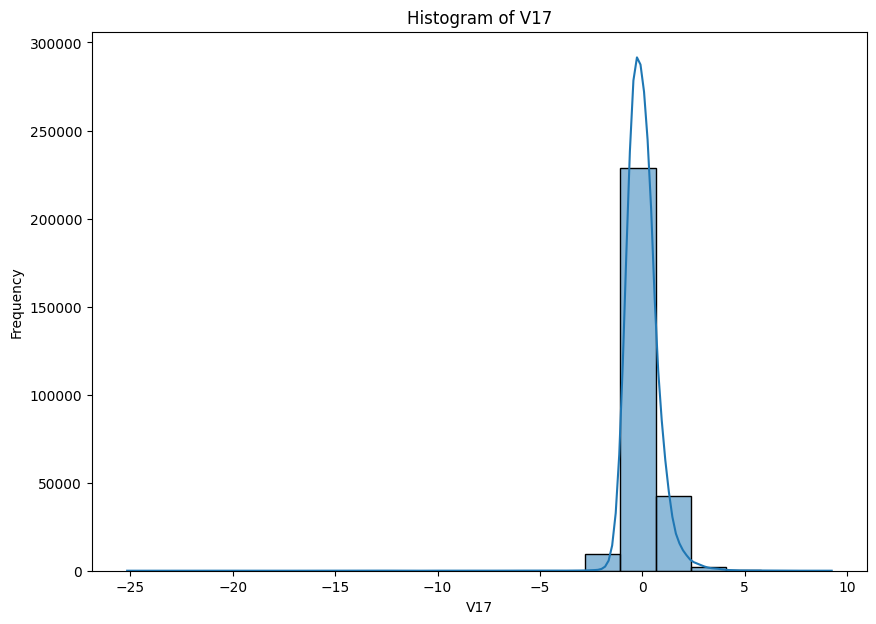

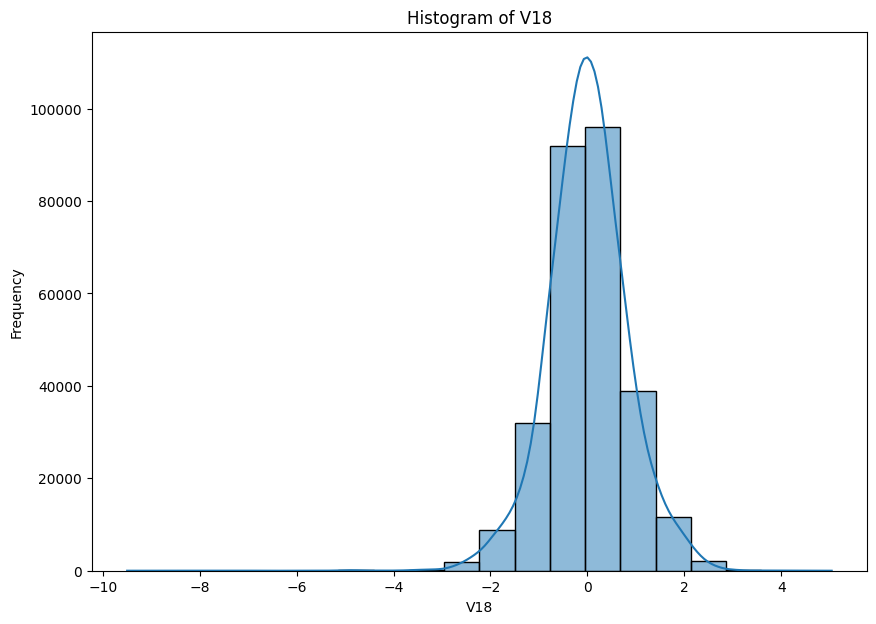

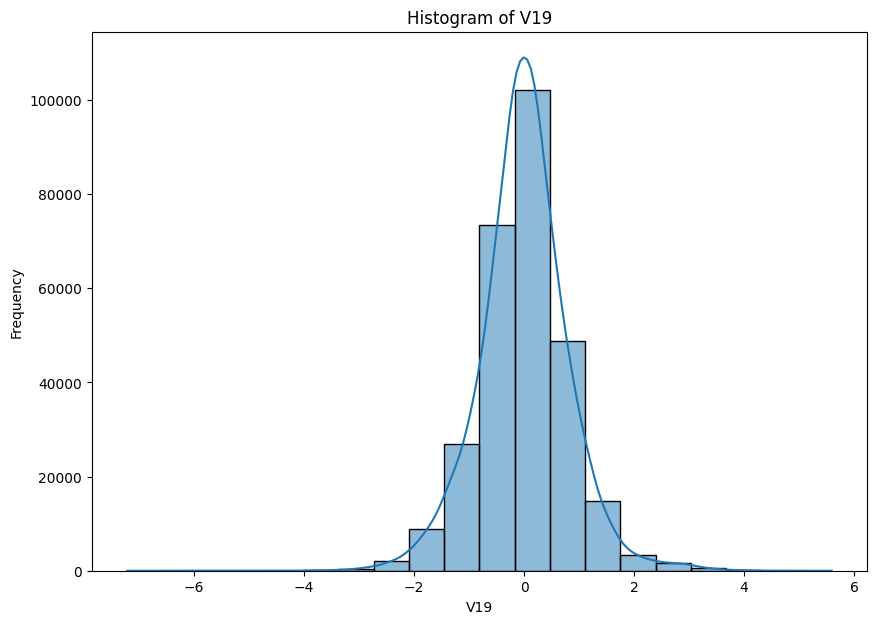

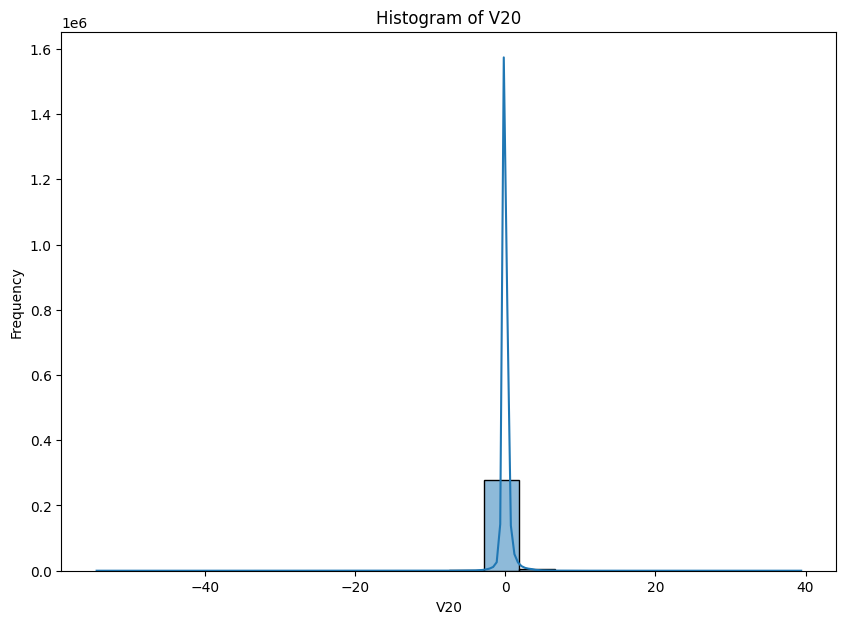

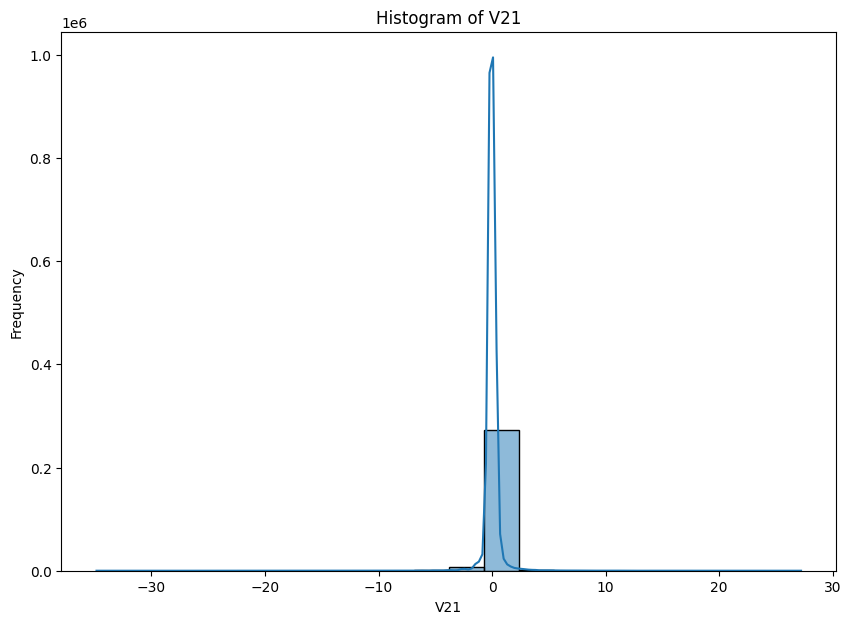

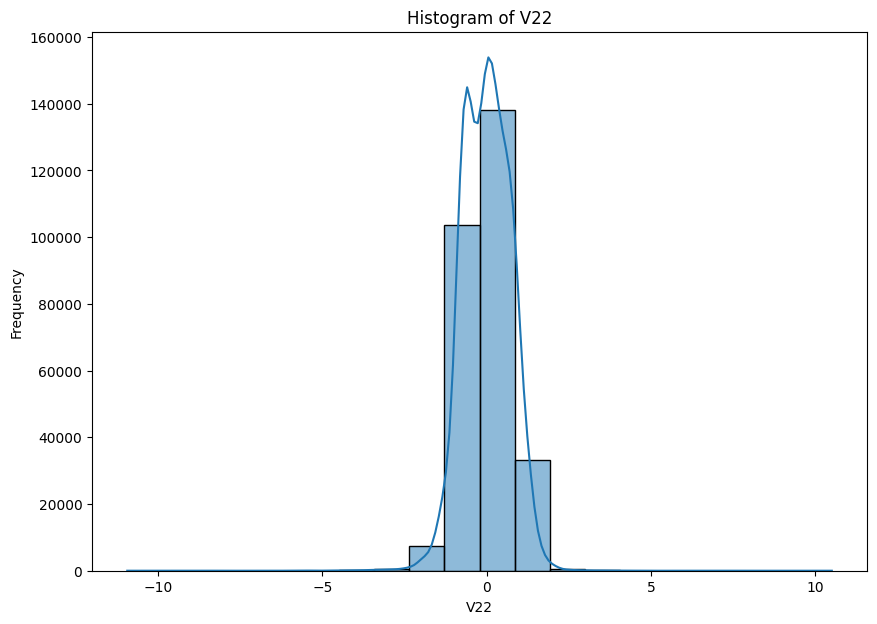

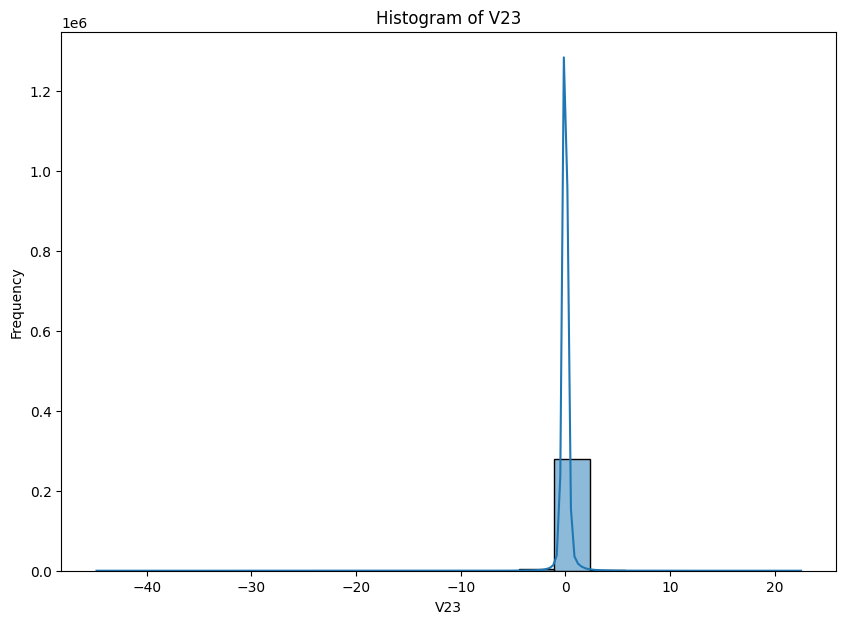

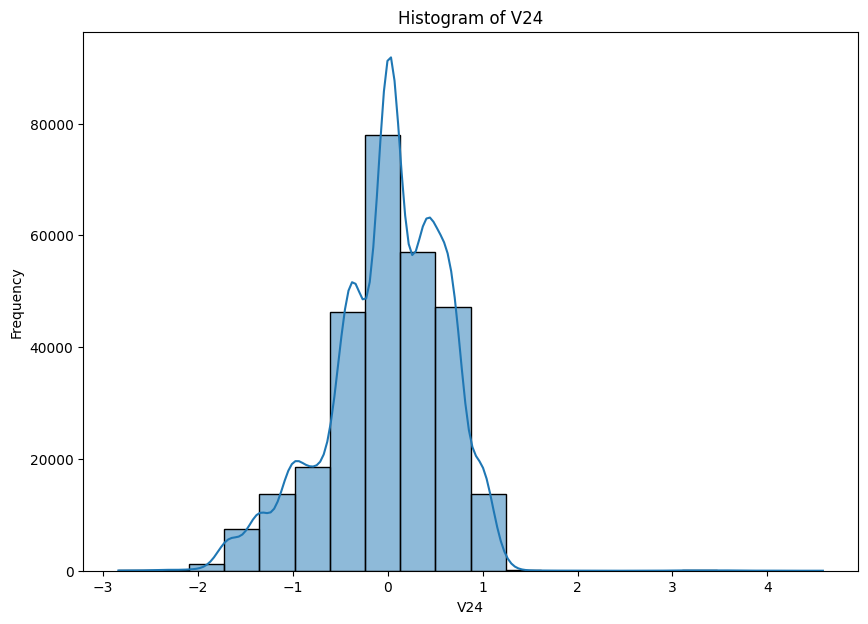

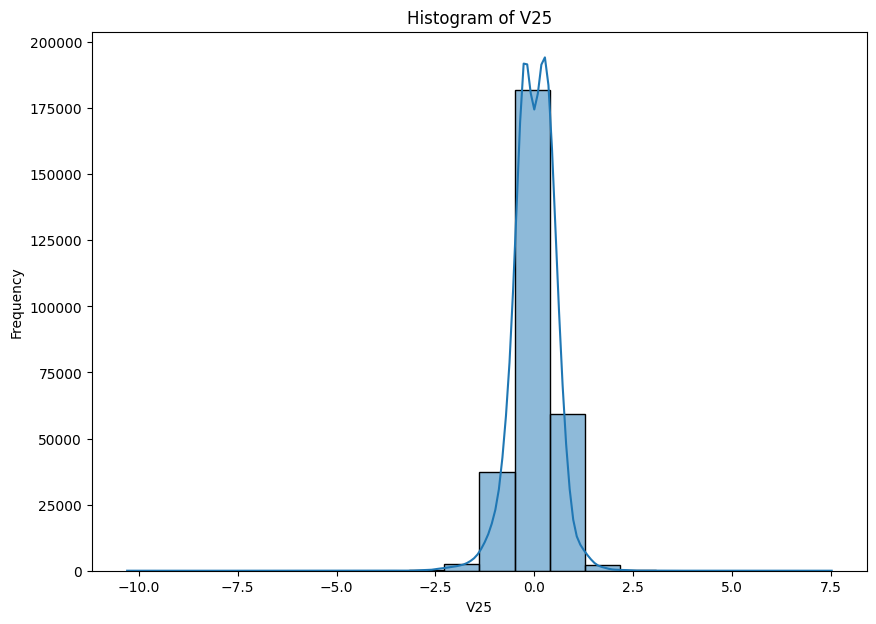

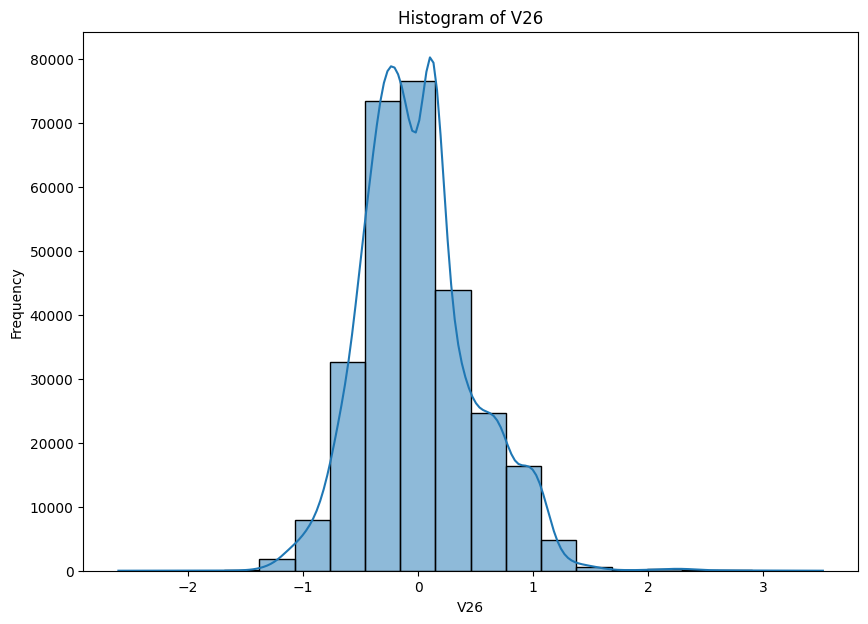

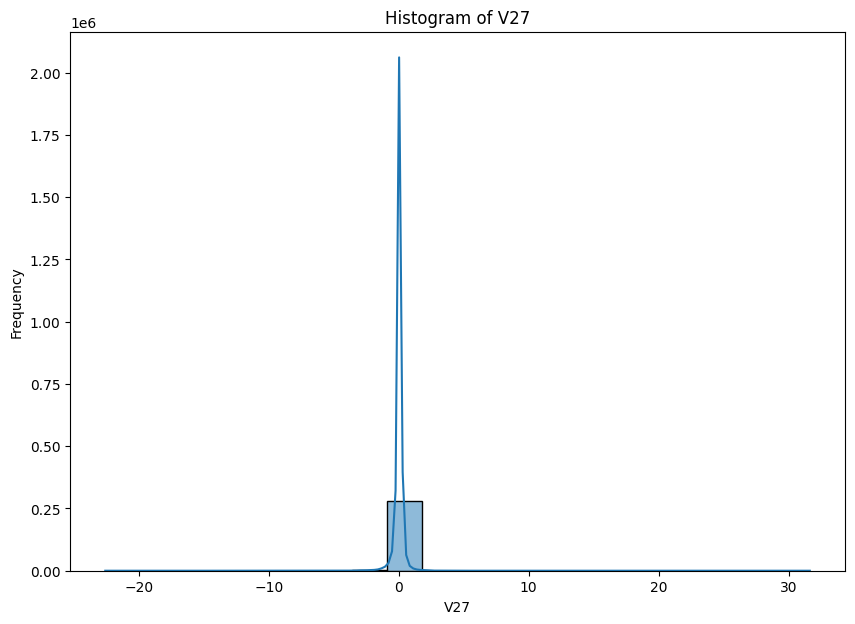

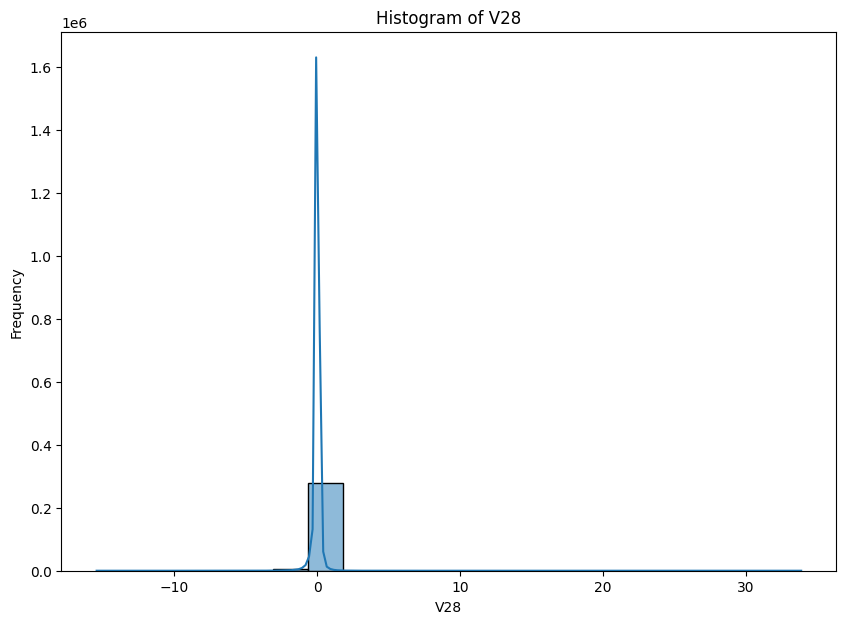

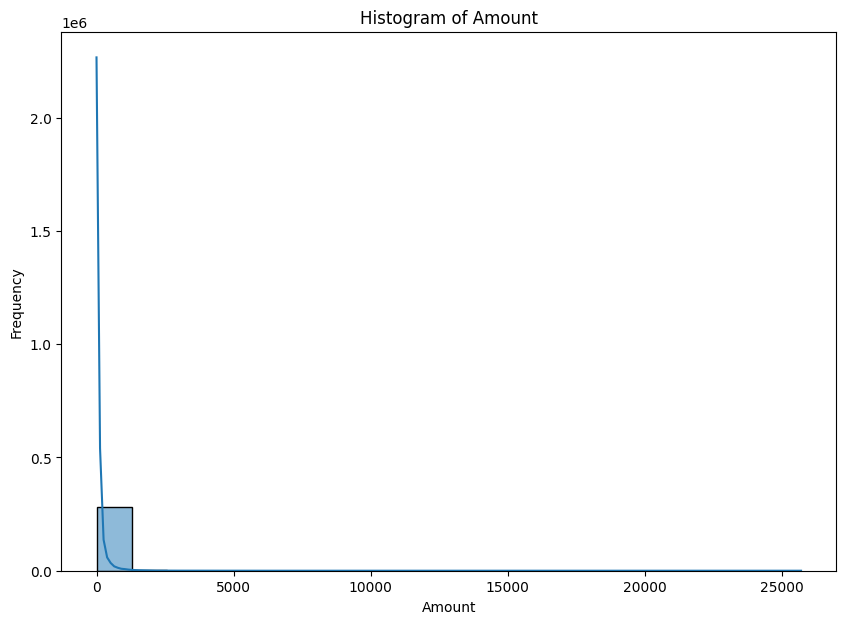

In [13]:
for col in df.drop(columns=["Class"]).columns:
    plt.figure(figsize=(10, 7))
    sns.histplot(data=df, x=col, bins=20,kde=True,kde_kws={'bw_adjust':2})
    plt.title(f"Histogram of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

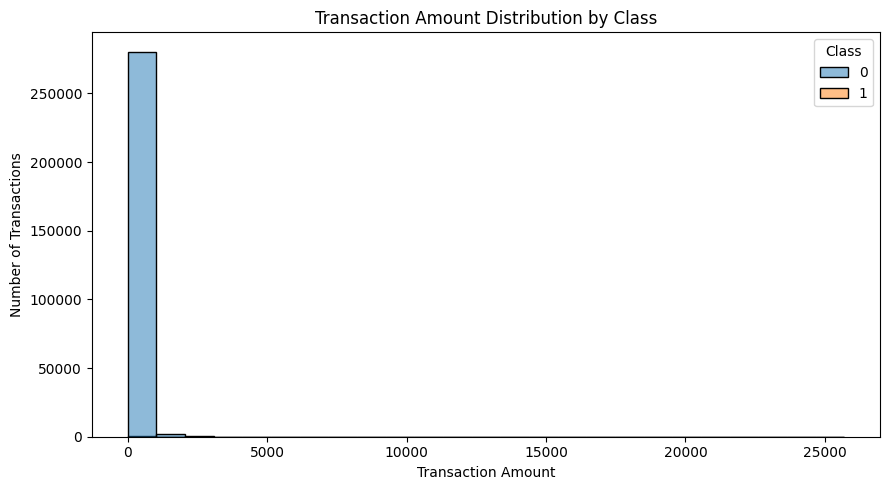

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=25,
    element="step",
    stat="count"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

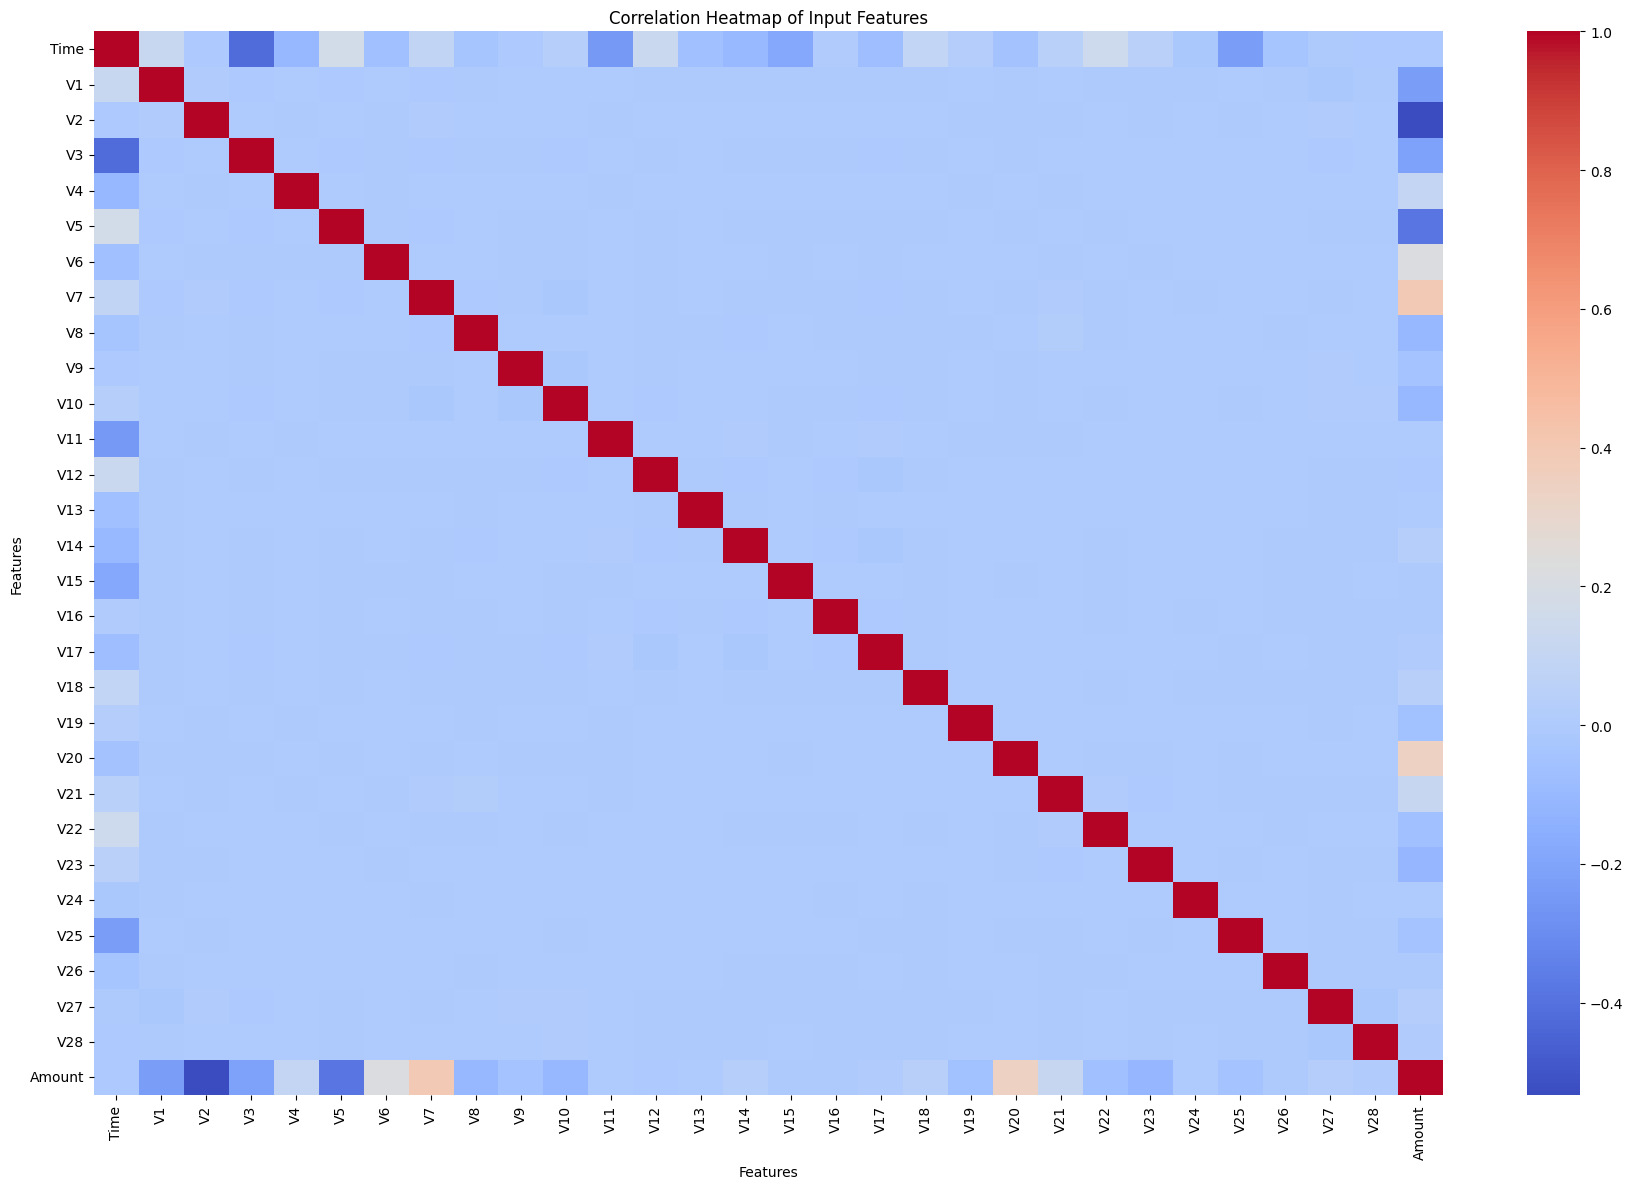

In [14]:
# Select input features only
X = df.drop(columns=["Class"])

# Calculate correlations between input features
correlation_matrix = X.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
)

plt.title("Correlation Heatmap of Input Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find pairs with absolute correlation greater than 0.7
high_correlations = (
    upper_triangle
    .stack()
    .reset_index()
)

high_correlations.columns = ["Feature 1", "Feature 2", "Correlation"]

high_correlations = high_correlations[
    high_correlations["Correlation"].abs() > 0.7
]

high_correlations = high_correlations.sort_values(
    by="Correlation",
    key=lambda values: values.abs(),
    ascending=False
)

print("Highly correlated feature pairs:")
print(high_correlations if not high_correlations.empty else "No pairs found above |correlation| = 0.7")

Highly correlated feature pairs:
No pairs found above |correlation| = 0.7


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Exclude the target column
X = df.drop(columns=["Class"])

# Use a sample to make calculation faster
X_sample = X.sample(
    n=min(10000, len(X)),
    random_state=42
)

# Calculate VIF
vif_results = pd.DataFrame({
    "Feature": X_sample.columns,
    "VIF": [
        variance_inflation_factor(X_sample.values, i)
        for i in range(X_sample.shape[1])
    ]
})

vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

print(vif_results.to_string(index=False))

Feature      VIF
 Amount 9.516829
     V2 4.209763
    V20 3.026826
     V7 2.614762
     V5 2.530649
   Time 1.877654
     V3 1.736699
     V1 1.514117
     V6 1.505137
    V21 1.182047
    V28 1.153721
    V10 1.135652
    V25 1.132663
    V11 1.120149
     V4 1.114323
     V8 1.104660
    V23 1.094814
    V22 1.076119
    V15 1.062524
    V27 1.061543
    V17 1.058873
    V14 1.055619
    V12 1.055492
    V18 1.053399
    V19 1.048804
     V9 1.038946
    V16 1.029819
    V13 1.010302
    V26 1.006082
    V24 1.003995


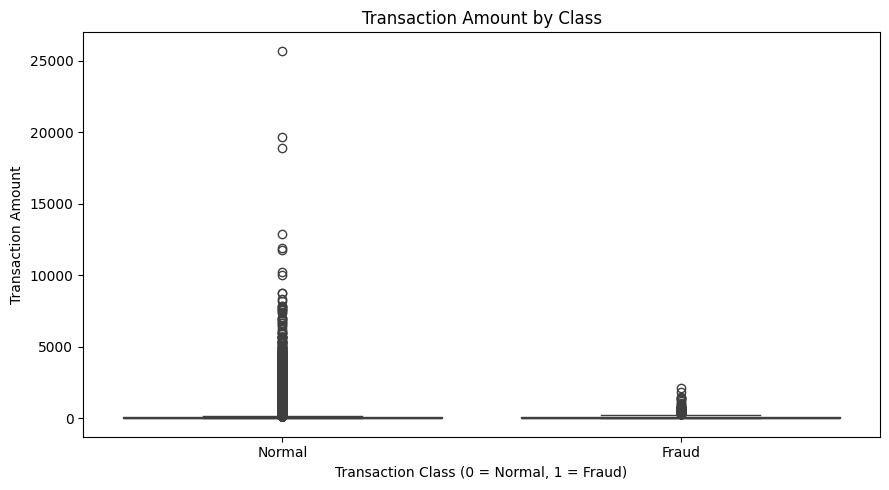

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.tight_layout()
plt.show()

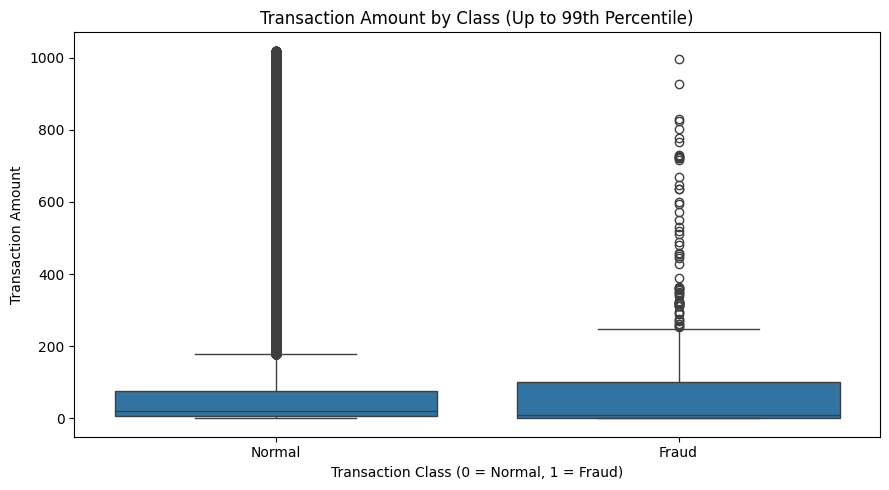

In [ ]:
amount_limit = df["Amount"].quantile(0.99)
df_zoom = df[df["Amount"] <= amount_limit]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_zoom,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount by Class (Up to 99th Percentile)")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.tight_layout()
plt.show()

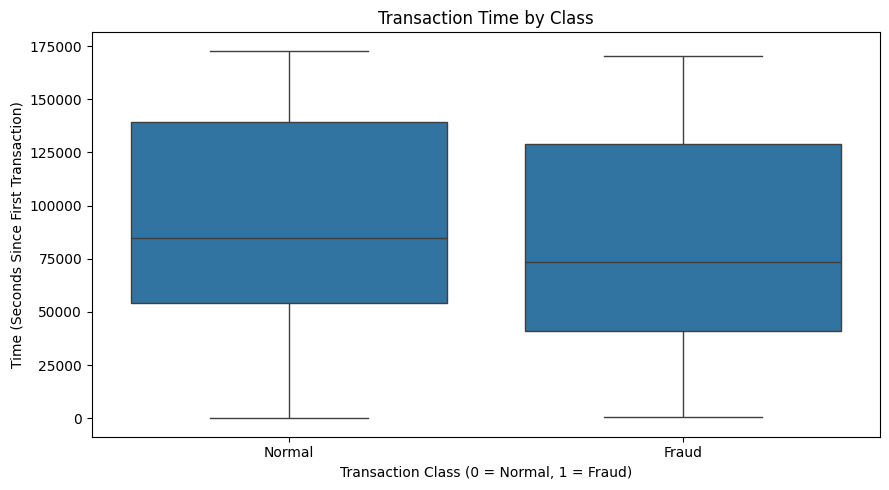

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Time"
)

plt.title("Transaction Time by Class")
plt.xlabel("Transaction Class (0 = Normal, 1 = Fraud)")
plt.ylabel("Time (Seconds Since First Transaction)")
plt.xticks([0, 1], ["Normal", "Fraud"])
plt.tight_layout()
plt.show()

In [ ]:
# Check outliers in Time, Amount, and V1–V28
features = df.drop(columns=["Class"]).columns

outlier_summary = []

for col in features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Limit": lower,
        "Upper Limit": upper,
        "Outlier Count": count
    })

outlier_df = pd.DataFrame(outlier_summary)

print(outlier_df.to_string(index=False))

Feature   Lower Limit   Upper Limit  Outlier Count
   Time -73435.125000 266937.875000              0
     V1     -4.263980      4.664096           6948
     V2     -2.701226      2.901188          13390
     V3     -3.764645      3.901923           3306
     V4     -3.234807      3.124319          11094
     V5     -2.642901      2.565290          12221
     V6     -2.517765      2.145527          22886
     V7     -2.236984      2.254949           8839
     V8     -1.010627      1.127502          23904
     V9     -2.504517      2.456273           8199
    V10     -2.019373      1.937414           9345
    V11     -3.013492      2.991422            735
    V12     -1.940959      2.151738          15282
    V13     -2.614423      2.629739           3362
    V14     -1.802834      1.869438          14060
    V15     -2.428786      2.497438           2884
    V16     -1.952416      2.009068           8180
    V17     -1.808277      1.723321           7353
    V18     -1.997969      2.00

In [ ]:
print("Amount skewness:", df["Amount"].skew())

Amount skewness: 16.978803370060476


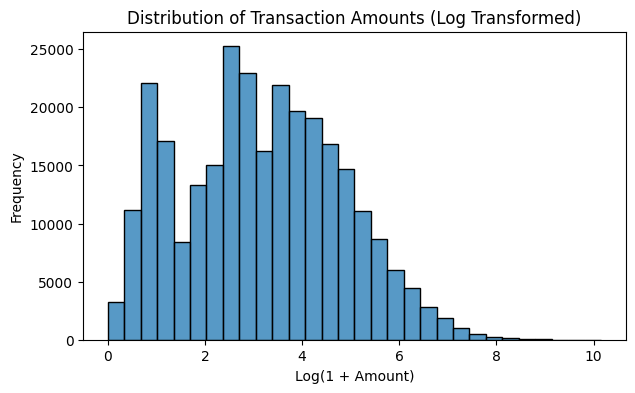

In [15]:
import numpy as np
plt.figure(figsize=(7, 4))

sns.histplot(x=np.log1p(df["Amount"]), bins=30)

plt.title("Distribution of Transaction Amounts (Log Transformed)")
plt.xlabel("Log(1 + Amount)")
plt.ylabel("Frequency")

plt.show()

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("successfully data splited")



successfully data splited


In [19]:
# Calculate IQR limits from training data only
Q1 = X_train["Amount"].quantile(0.25)
Q3 = X_train["Amount"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: -102.55
Upper limit: 186.08999999999997


In [20]:
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

X_train_capped["Amount"] = X_train_capped["Amount"].clip(
    upper=upper_limit
)

X_test_capped["Amount"] = X_test_capped["Amount"].clip(
    upper=upper_limit
)

print("Training values capped:",
      (X_train["Amount"] > upper_limit).sum())

print("Testing values capped:",
      (X_test["Amount"] > upper_limit).sum())

Training values capped: 25316
Testing values capped: 6267


In [21]:
print("Training shape:", X_train_capped.shape)
print("Testing shape:", X_test_capped.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training shape: (226980, 30)
Testing shape: (56746, 30)

Training class distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing class distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [22]:
from sklearn.preprocessing import StandardScaler

# Uncapped version
scaler_uncapped = StandardScaler()
X_train_uncapped_scaled = scaler_uncapped.fit_transform(X_train)
X_test_uncapped_scaled = scaler_uncapped.transform(X_test)

# Capped version
scaler_capped = StandardScaler()
X_train_capped_scaled = scaler_capped.fit_transform(X_train_capped)
X_test_capped_scaled = scaler_capped.transform(X_test_capped)

print("Both capped and uncapped datasets are ready.")

Both capped and uncapped datasets are ready.


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

experiments = {
    "Uncapped": X_train,
    "Capped": X_train_capped
}

results = {}

for name, X_data in experiments.items():
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model,
        X_data,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=-1
    )

    model.fit(X_data, y_train)

    X_test_data = X_test if name == "Uncapped" else X_test_capped
    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1]

    results[name] = {
        "model": model,
        "CV Average Precision": scores.mean(),
        "Test Average Precision": average_precision_score(y_test, y_prob),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    }

for name, result in results.items():
    print(f"\n--- {name} Logistic Regression ---")
    for metric, value in result.items():
        if metric != "model":
            print(f"{metric}: {value:.4f}")


--- Uncapped Logistic Regression ---
CV Average Precision: 0.7543
Test Average Precision: 0.6719
Precision: 0.0564
Recall: 0.8737
F1 Score: 0.1059

--- Capped Logistic Regression ---
CV Average Precision: 0.7575
Test Average Precision: 0.6778
Precision: 0.0557
Recall: 0.8737
F1 Score: 0.1047


In [51]:

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 3-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create the best LR pipeline
lr_best = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Cross-validation using training data
cv_scores = cross_val_score(
    lr_best,
    X_train_capped,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1
)

# Train on the complete training set
lr_best.fit(X_train_capped, y_train)

# Predict on the test set
y_pred_lr = lr_best.predict(X_test_capped)
y_prob_lr = lr_best.predict_proba(X_test_capped)[:, 1]

# Evaluate
print("Logistic Regression with SMOTE (Capped Data)")
print(f"CV Average Precision: {cv_scores.mean():.4f}")
print(f"Test Average Precision: {average_precision_score(y_test, y_prob_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr, zero_division=0):.4f}")
print(f"F1 Score: {f1_score(y_test, y_pred_lr, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))


Logistic Regression with SMOTE (Capped Data)
CV Average Precision: 0.7553
Test Average Precision: 0.6839
Precision: 0.0529
Recall: 0.8737
F1 Score: 0.0998

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.87      0.10        95

    accuracy                           0.97     56746
   macro avg       0.53      0.92      0.54     56746
weighted avg       1.00      0.97      0.99     56746




Current interpretation:
- Highest Average Precision: capped + SMOTE.
- Highest precision and F1-score: uncapped without SMOTE.
- Recall is identical across all four experiments.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

experiments = {
    "Uncapped": (X_train, X_test),
    "Capped": (X_train_capped, X_test_capped)
}

rf_results = {}

for name, (X_tr, X_te) in experiments.items():
    model = RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )

    cv_scores = cross_val_score(
        model,
        X_tr,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    model.fit(X_tr, y_train)

    predictions = model.predict(X_te)
    probabilities = model.predict_proba(X_te)[:, 1]

    rf_results[name] = {
        "model": model,
        "CV Average Precision": cv_scores.mean(),
        "Test Average Precision": average_precision_score(
            y_test, probabilities
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    print(f"\n--- {name} Random Forest ---")
    for metric, value in rf_results[name].items():
        if metric != "model":
            print(f"{metric}: {value:.4f}")


--- Uncapped Random Forest ---
CV Average Precision: 0.8288
Test Average Precision: 0.7978
Precision: 0.9710
Recall: 0.7053
F1 Score: 0.8171

--- Capped Random Forest ---
CV Average Precision: 0.8308
Test Average Precision: 0.8100
Precision: 0.9714
Recall: 0.7158
F1 Score: 0.8242


In [26]:
from sklearn.metrics import average_precision_score

for name, (X_tr, X_te) in {
    "Uncapped": (X_train, X_test),
    "Capped": (X_train_capped, X_test_capped)
}.items():

    model = rf_results[name]["model"]

    train_prob = model.predict_proba(X_tr)[:, 1]
    test_prob = model.predict_proba(X_te)[:, 1]

    train_ap = average_precision_score(y_train, train_prob)
    test_ap = average_precision_score(y_test, test_prob)
    cv_ap = rf_results[name]["CV Average Precision"]

    print(f"\n--- {name} Random Forest ---")
    print(f"Training Average Precision: {train_ap:.4f}")
    print(f"CV Average Precision:      {cv_ap:.4f}")
    print(f"Test Average Precision:    {test_ap:.4f}")
    print(f"Train-CV gap:               {train_ap - cv_ap:.4f}")


--- Uncapped Random Forest ---
Training Average Precision: 1.0000
CV Average Precision:      0.8288
Test Average Precision:    0.7978
Train-CV gap:               0.1712

--- Capped Random Forest ---
Training Average Precision: 1.0000
CV Average Precision:      0.8308
Test Average Precision:    0.8100
Train-CV gap:               0.1692


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import average_precision_score

cv = StratifiedKFold(
    n_splits=3, shuffle=True, random_state=42
)

# Use capped data, which performed better so far
X_tr = X_train_capped
X_te = X_test_capped

models = {
    "Baseline RF": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "Regularized RF": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    cv_scores = cross_val_score(
        model,
        X_tr,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=1
    )

    model.fit(X_tr, y_train)

    train_prob = model.predict_proba(X_tr)[:, 1]
    test_prob = model.predict_proba(X_te)[:, 1]

    train_ap = average_precision_score(y_train, train_prob)
    test_ap = average_precision_score(y_test, test_prob)

    print(f"\n--- {name} ---")
    print(f"Training Average Precision: {train_ap:.4f}")
    print(f"CV Average Precision:      {cv_scores.mean():.4f}")
    print(f"Test Average Precision:    {test_ap:.4f}")
    print(f"Train-CV gap:              {train_ap - cv_scores.mean():.4f}")


--- Baseline RF ---
Training Average Precision: 1.0000
CV Average Precision:      0.8308
Test Average Precision:    0.8100
Train-CV gap:              0.1692

--- Regularized RF ---
Training Average Precision: 0.9786
CV Average Precision:      0.8246
Test Average Precision:    0.8045
Train-CV gap:              0.1540


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf = RandomForestClassifier(
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

param_dist = {
    "n_estimators": [50, 100],
    "max_depth": [10, 15, 20],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5],
    "max_features": ["sqrt"]
}

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=4,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=True
)

search.fit(X_train_capped, y_train)

print("\nBest CV Average Precision:", round(search.best_score_, 4))
print("Best hyperparameters:", search.best_params_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  28.2s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  27.5s
[CV] END max_depth=15, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  29.9s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  28.1s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  28.2s
[CV] END max_depth=20, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  30.2s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total time=  26.9s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=2, min_samples_split=5, n_estimators=50; total t

In [30]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Best model selected by RandomizedSearchCV
best_rf = search.best_estimator_

# Predictions
y_train_prob = best_rf.predict_proba(X_train_capped)[:, 1]
y_test_prob = best_rf.predict_proba(X_test_capped)[:, 1]
y_test_pred = best_rf.predict(X_test_capped)

# Average Precision
train_ap = average_precision_score(y_train, y_train_prob)
test_ap = average_precision_score(y_test, y_test_prob)

print("Training Average Precision:", round(train_ap, 4))
print("Cross-Validation Average Precision:", round(search.best_score_, 4))
print("Test Average Precision:", round(test_ap, 4))

# Classification metrics
print("\nPrecision:", round(precision_score(y_test, y_test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Training Average Precision: 0.9911
Cross-Validation Average Precision: 0.8307
Test Average Precision: 0.8113

Precision: 0.9324
Recall: 0.7263
F1 Score: 0.8166

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.73      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [31]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate class imbalance ratio from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_weight = negative_count / positive_count

# Initialize XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    xgb_model,
    X_train_capped,
    y_train,
    scoring="average_precision",
    cv=cv,
    n_jobs=1
)

# Train final model
xgb_model.fit(X_train_capped, y_train)

# Predictions
y_train_prob = xgb_model.predict_proba(X_train_capped)[:, 1]
y_test_prob = xgb_model.predict_proba(X_test_capped)[:, 1]
y_test_pred = xgb_model.predict(X_test_capped)

# Evaluation
print("Training Average Precision:",
      round(average_precision_score(y_train, y_train_prob), 4))

print("CV Average Precision Scores:", cv_scores.round(4))
print("Mean CV Average Precision:", round(cv_scores.mean(), 4))

print("Test Average Precision:",
      round(average_precision_score(y_test, y_test_prob), 4))

print("Precision:",
      round(precision_score(y_test, y_test_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, y_test_pred, zero_division=0), 4))

print("F1 Score:",
      round(f1_score(y_test, y_test_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Training Average Precision: 0.9795
CV Average Precision Scores: [0.8328 0.8082 0.8717]
Mean CV Average Precision: 0.8376
Test Average Precision: 0.8057
Precision: 0.7379
Recall: 0.8
F1 Score: 0.7677

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.74      0.80      0.77        95

    accuracy                           1.00     56746
   macro avg       0.87      0.90      0.88     56746
weighted avg       1.00      1.00      1.00     56746



- Average Precision (CV): XGBoost scores slightly higher at 0.8376, suggesting promising performance across training folds.
- Test Average Precision: Random Forest is slightly better, scoring 0.8113 versus 0.8057.
- Precision: Random Forest is better. Of the transactions it flags as fraud, 93.24% are fraudulent.
- Recall: XGBoost is better. It detects 80% of fraud cases, compared with 72.63% for Random Forest.
- F1-score: Random Forest has the better balance of precision and recall at the current default prediction thresholds.
Your test set contains 95 fraud cases. XGBoost detected 76 and missed 19. Random Forest detected approximately 69 and missed 26.

In [32]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

xgb = XGBClassifier(
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

param_dist = {
    "n_estimators": [100, 150],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_dist,
    n_iter=6,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=True
)

xgb_search.fit(X_train_capped, y_train)

print("\nBest CV Average Precision:",
      round(xgb_search.best_score_, 4))

print("Best hyperparameters:")
print(xgb_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=3, n_estimators=150, subsample=1.0; total time=   4.9s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=3, n_estimators=150, subsample=1.0; total time=   2.4s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=3, n_estimators=150, subsample=1.0; total time=   2.6s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=0.8; total time=   2.5s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=0.8; total time=   2.5s
[CV] END colsample_bytree=1.0, learning_rate=0.1, max_depth=5, n_estimators=100, subsample=0.8; total time=   2.6s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=3, n_estimators=150, subsample=0.8; total time=   2.7s
[CV] END colsample_bytree=1.0, learning_rate=0.05, max_depth=3, n_estimators=150, subsample=0.8; total time=   2.7s
[CV] END colsam

In [33]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Get the best model from tuning
best_xgb = xgb_search.best_estimator_

# Predict probabilities and classes
y_train_prob_xgb = best_xgb.predict_proba(X_train_capped)[:, 1]
y_test_prob_xgb = best_xgb.predict_proba(X_test_capped)[:, 1]
y_test_pred_xgb = best_xgb.predict(X_test_capped)

# Average Precision
train_ap_xgb = average_precision_score(y_train, y_train_prob_xgb)
test_ap_xgb = average_precision_score(y_test, y_test_prob_xgb)

print("Training Average Precision:", round(train_ap_xgb, 4))
print("Cross-Validation Average Precision:", round(xgb_search.best_score_, 4))
print("Test Average Precision:", round(test_ap_xgb, 4))

# Classification metrics
print("\nPrecision:", round(precision_score(y_test, y_test_pred_xgb, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred_xgb, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_test_pred_xgb, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_xgb, zero_division=0))

Training Average Precision: 0.9964
Cross-Validation Average Precision: 0.8432
Test Average Precision: 0.8139

Precision: 0.8621
Recall: 0.7895
F1 Score: 0.8242

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.86      0.79      0.82        95

    accuracy                           1.00     56746
   macro avg       0.93      0.89      0.91     56746
weighted avg       1.00      1.00      1.00     56746



In [34]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

regularized_xgb = XGBClassifier(
    n_estimators=150,
    max_depth=3,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=5,
    scale_pos_weight=scale_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    regularized_xgb,
    X_train_capped,
    y_train,
    scoring="average_precision",
    cv=cv,
    n_jobs=1
)

regularized_xgb.fit(X_train_capped, y_train)

train_prob = regularized_xgb.predict_proba(X_train_capped)[:, 1]
test_prob = regularized_xgb.predict_proba(X_test_capped)[:, 1]
test_pred = regularized_xgb.predict(X_test_capped)

print("Training Average Precision:",
      round(average_precision_score(y_train, train_prob), 4))
print("CV Average Precision Scores:", cv_scores.round(4))
print("Mean CV Average Precision:", round(cv_scores.mean(), 4))
print("Test Average Precision:",
      round(average_precision_score(y_test, test_prob), 4))
print("Precision:", round(precision_score(y_test, test_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, test_pred, zero_division=0), 4))

Training Average Precision: 0.7585
CV Average Precision Scores: [0.7554 0.7291 0.7575]
Mean CV Average Precision: 0.7473
Test Average Precision: 0.6639
Precision: 0.1582
Recall: 0.8526
F1 Score: 0.2669


In [52]:

import pandas as pd

results = [
    {"Model": "Logistic Regression (Uncapped)", "CV AP": 0.7543, "Test AP": 0.6719, "Precision": 0.0564, "Recall": 0.8737, "F1 Score": 0.1059},
    {"Model": "Logistic Regression (Capped)", "CV AP": 0.7575, "Test AP": 0.6778, "Precision": 0.0557, "Recall": 0.8737, "F1 Score": 0.1047},
    {"Model": "Logistic Regression (Capped + SMOTE)", "CV AP": 0.7553, "Test AP": 0.6839, "Precision": 0.0529, "Recall": 0.8737, "F1 Score": 0.0998},
    {"Model": "Random Forest (Baseline, Capped)", "CV AP": 0.8308, "Test AP": 0.8100, "Precision": 0.9714, "Recall": 0.7158, "F1 Score": 0.8242},
    {"Model": "Random Forest (Tuned)", "CV AP": 0.8307, "Test AP": 0.8113, "Precision": 0.9324, "Recall": 0.7263, "F1 Score": 0.8166},
    {"Model": "XGBoost (Baseline)", "CV AP": 0.8376, "Test AP": 0.8057, "Precision": 0.7379, "Recall": 0.8000, "F1 Score": 0.7677},
    {"Model": "XGBoost (Tuned)", "CV AP": 0.8432, "Test AP": 0.8139, "Precision": 0.8621, "Recall": 0.7895, "F1 Score": 0.8242},
    {"Model": "XGBoost (Regularized)", "CV AP": 0.7473, "Test AP": 0.6639, "Precision": 0.1582, "Recall": 0.8526, "F1 Score": 0.2669}
]

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Test AP",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,CV AP,Test AP,Precision,Recall,F1 Score
0,XGBoost (Tuned),0.8432,0.8139,0.8621,0.7895,0.8242
1,Random Forest (Tuned),0.8307,0.8113,0.9324,0.7263,0.8166
2,"Random Forest (Baseline, Capped)",0.8308,0.8100,0.9714,0.7158,0.8242
3,XGBoost (Baseline),0.8376,0.8057,0.7379,0.8000,0.7677
4,Logistic Regression (Capped + SMOTE),0.7553,0.6839,0.0529,0.8737,0.0998
5,Logistic Regression (Capped),0.7575,0.6778,0.0557,0.8737,0.1047
6,Logistic Regression (Uncapped),0.7543,0.6719,0.0564,0.8737,0.1059
7,XGBoost (Regularized),0.7473,0.6639,0.1582,0.8526,0.2669


Best current candidate: Tuned XGBoost, with test Average Precision of 0.8139.



Highest precision: Baseline Random Forest, at 0.9714.



Highest recall: Logistic Regression in the listed experiments, at 0.8737, although its precision is very low.



Regularized XGBoost: Not preferred because both CV and test Average Precision decreased .


Tuned XGBoost
Average Precision: 0.8139

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.86      0.79      0.82        95

    accuracy                           1.00     56746
   macro avg       0.93      0.89      0.91     56746
weighted avg       1.00      1.00      1.00     56746



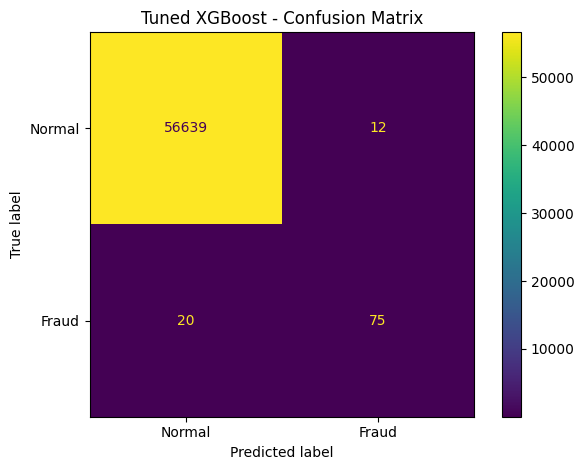

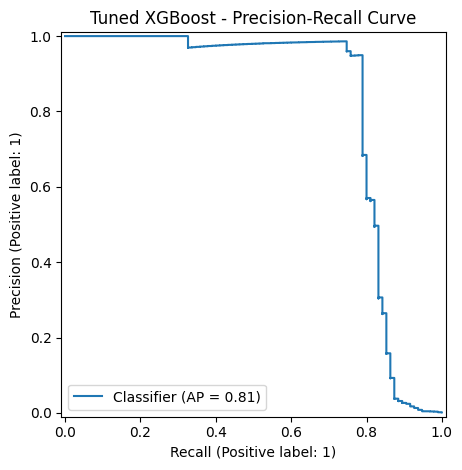


Tuned Random Forest
Average Precision: 0.8113

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.93      0.73      0.82        95

    accuracy                           1.00     56746
   macro avg       0.97      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



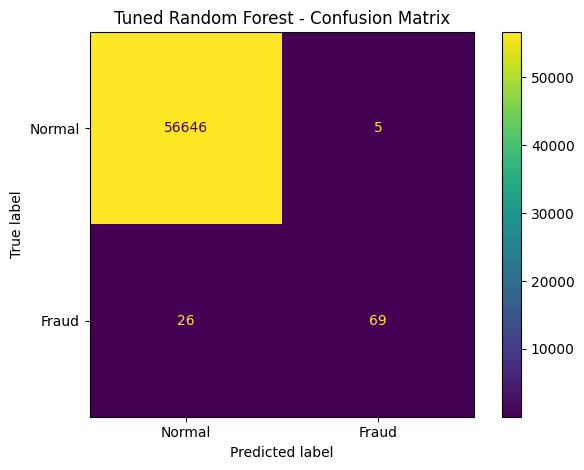

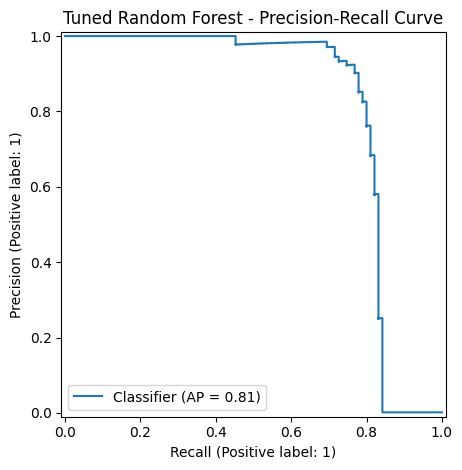

In [36]:

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

models = {
    "Tuned XGBoost": best_xgb,
    "Tuned Random Forest": best_rf
}

# Compare the two fitted models
for name, model in models.items():
    y_pred = model.predict(X_test_capped)
    y_scores = model.predict_proba(X_test_capped)[:, 1]

    print(f"\n{'=' * 50}")
    print(name)
    print(f"Average Precision: {average_precision_score(y_test, y_scores):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        display_labels=["Normal", "Fraud"],
        values_format="d"
    )
    plt.title(f"{name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

    PrecisionRecallDisplay.from_predictions(
        y_test, y_scores
    )
    plt.title(f"{name} - Precision-Recall Curve")
    plt.tight_layout()
    plt.show()


Top 10 Important Features:
V14       0.498880
V4        0.056857
V12       0.034336
V8        0.033845
V10       0.028994
V3        0.024644
V19       0.022862
V13       0.021139
Amount    0.019463
V21       0.018285
dtype: float32


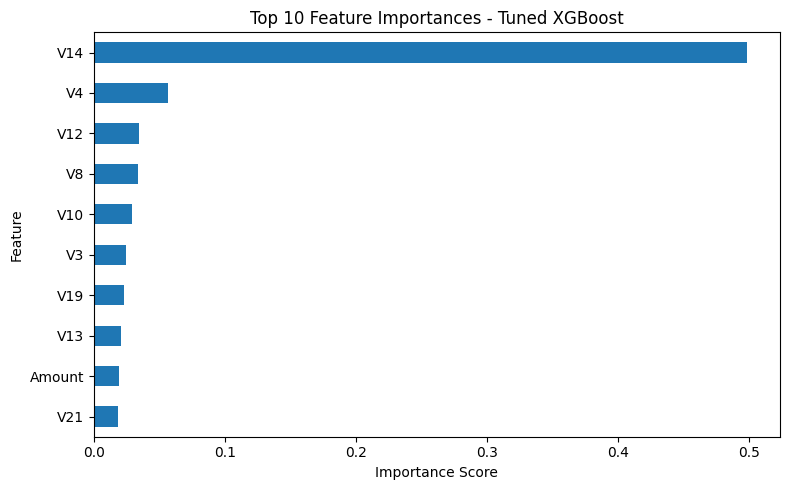

In [37]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    best_xgb.feature_importances_,
    index=X_test_capped.columns
).sort_values(ascending=False)

print("Top 10 Important Features:")
print(importance.head(10))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top 10 Feature Importances - Tuned XGBoost")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


V14 is the dominant feature, accounting for approximately 49.9% of the model's reported feature-importance scores.



V4 is the second most important feature, at approximately 5.7%.



Amount appears in ninth place, so the transaction amount contributes to the model's predictions but is not its leading feature.



V1–V28 are anonymized features derived from a PCA transformation in the original dataset. We cannot directly assign everyday meanings to V14, V4, or the other V-features from their names alone.

In [43]:

print("Models dictionary contents:")

for name, obj in models.items():
    print(f"{name}: {type(obj).__name__}")


Models dictionary contents:
Tuned XGBoost: XGBClassifier
Tuned Random Forest: RandomForestClassifier


In [45]:
import joblib
from pathlib import Path

model_dir = Path("saved_models")
model_dir.mkdir(exist_ok=True)

models_to_save = {
    "tuned_random_forest": best_rf,
    "tuned_xgboost": best_xgb
}

for name, fitted_model in models_to_save.items():
    path = model_dir / f"{name}.joblib"
    joblib.dump(fitted_model, path)
    print(f"Saved: {path}")

print("\nBoth fitted models have been saved.")


Saved: saved_models/tuned_random_forest.joblib
Saved: saved_models/tuned_xgboost.joblib

Both fitted models have been saved.


In [53]:
from pathlib import Path
import joblib

# Create folder
Path("saved_models").mkdir(exist_ok=True)

# Save the best Logistic Regression model
joblib.dump(
    lr_best,
    "saved_models/logistic_regression.joblib"
)

print("Logistic Regression saved successfully!")


Logistic Regression saved successfully!


In [54]:
from pathlib import Path

folder = Path("saved_models")

print("Saved model files:")
for file in sorted(folder.glob("*.joblib")):
    print(f"- {file}")


Saved model files:
- saved_models/logistic_regression.joblib
- saved_models/tuned_random_forest.joblib
- saved_models/tuned_xgboost.joblib


In [55]:

import joblib
from pathlib import Path

model_files = {
    "Logistic Regression": "saved_models/logistic_regression.joblib",
    "Random Forest": "saved_models/tuned_random_forest.joblib",
    "XGBoost": "saved_models/tuned_xgboost.joblib"
}

for name, path in model_files.items():
    model = joblib.load(path)

    if name == "Logistic Regression":
        X_sample = X_test_capped.iloc[:5]
    else:
        X_sample = X_test_capped.iloc[:5]

    predictions = model.predict(X_sample)

    print(f"{name}:")
    print("  Loaded:", type(model).__name__)
    print("  Predictions:", predictions)
    print()


Logistic Regression:
  Loaded: Pipeline
  Predictions: [0 0 0 0 0]

Random Forest:
  Loaded: RandomForestClassifier
  Predictions: [0 0 0 0 0]

XGBoost:
  Loaded: XGBClassifier
  Predictions: [0 0 0 0 0]



In [56]:
import joblib

models = {
    "Tuned XGBoost": joblib.load(
        "saved_models/tuned_xgboost.joblib"
    ),
    "Tuned Random Forest": joblib.load(
        "saved_models/tuned_random_forest.joblib"
    )
}

In [57]:
import joblib
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Tuned Random Forest": joblib.load(
        "saved_models/tuned_random_forest.joblib"
    ),
    "Tuned XGBoost": joblib.load(
        "saved_models/tuned_xgboost.joblib"
    )
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test_capped)
    y_scores = model.predict_proba(X_test_capped)[:, 1]

    results.append({
        "Model": name,
        "Test Average Precision": round(
            average_precision_score(y_test, y_scores), 4
        ),
        "Precision": round(
            precision_score(y_test, y_pred, zero_division=0), 4
        ),
        "Recall": round(
            recall_score(y_test, y_pred, zero_division=0), 4
        ),
        "F1 Score": round(
            f1_score(y_test, y_pred, zero_division=0), 4
        )
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Test Average Precision,Precision,Recall,F1 Score
0,Tuned Random Forest,0.8113,0.9324,0.7263,0.8166
1,Tuned XGBoost,0.8139,0.8621,0.7895,0.8242


In [58]:
comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [59]:
from google.colab import files
files.download("model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
import os

for root, dirs, files_list in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in ["sample_data", ".config", "__pycache__"]
    ]

    for file in files_list:
        if file.endswith((".ipynb", ".joblib", ".csv", ".py", ".txt", ".md")):
            print(os.path.join(root, file))

./creditcard.csv
./model_comparison.csv
./saved_models/tuned_random_forest.joblib
./saved_models/tuned_xgboost.joblib
./saved_models/logistic_regression.joblib
